# 구글 코랩 마운트

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 라이브러리 임포트

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import torch

# 한글 폰트

In [ ]:
apt-get update
apt-get install -y fonts-nanum fonts-nanum-coding
fc-list | grep -i nanum
apt-get update -qq
apt-get install fonts-nanum -qq

SyntaxError: invalid syntax (3706593733.py, line 2)

In [3]:

font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
font_name = fm.FontProperties(fname=font_path).get_name()

plt.rc("font", family=font_name)
plt.rcParams["axes.unicode_minus"] = False

print("✅ 한글 폰트 적용 완료:", font_name)
# ✅ 실제 존재하는 폰트 경로
font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"

# ✅ 폰트 매니저에 강제 등록
fm.fontManager.addfont(font_path)

# ✅ matplotlib에 직접 적용 (이 방식이 가장 확실)
plt.rcParams["font.family"] = fm.FontProperties(fname=font_path).get_name()
plt.rcParams["axes.unicode_minus"] = False

# 확인 출력
print("✅ 적용 폰트:", plt.rcParams["font.family"])

FileNotFoundError: [Errno 2] No such file or directory: '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'

# gpu 확인

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("사용 디바이스:", device)

사용 디바이스: cpu


# 메타 데이터 확인

In [ ]:
df = pd.read_csv(
    "/content/drive/MyDrive/data_list_final_v2.csv",
    encoding="utf-8",
    engine="python"
)
df.head()

,공고 번호,공고 차수,사업명,project_id,사업 금액,발주 기관,공개 일자,입찰 참여 시작일,입찰 참여 마감일,사업 요약,파일명
0,20241001798,0,한영대학교 특성화 맞춤형 교육환경 구축 - 트랙운영 학사정보시스템 고도화,proj_001,130000000.0,한영대학,04/10/2024 13:51,04/10/2024 13:51,15/10/2024 17:00,- 한영대학교 특성화 맞춤형 교육환경 구축을 위해 트랙운영 학사정보시스템을 고도화한...,한영대학_한영대학교 특성화 맞춤형 교육환경 구축 - 트랙운영 학사정보.hwp
1,20241002912,0,2024년 대학산학협력활동 실태조사 시스템(UICC) 기능개선,proj_002,129300000.0,한국연구재단,04/10/2024 15:01,14/10/2024 10:00,16/10/2024 14:00,- 사업 개요: 2024년 대학 산학협력활동 실태조사 시스템(UICC) 기능개선\n...,한국연구재단_2024년 대학산학협력활동 실태조사 시스템(UICC) 기능개선.hwp
2,20240827859,0,EIP3.0 고압가스 안전관리 시스템 구축 용역,proj_003,40000000.0,한국생산기술연구원,28/08/2024 11:31,29/08/2024 09:00,09/09/2024 10:00,- 사업 개요: EIP3.0 고압가스 안전관리 시스템 구축 용역\n- 추진배경: 안...,한국생산기술연구원_EIP3.0 고압가스 안전관리 시스템 구축 용역.hwp
3,20240430918,0,도시계획위원회 통합관리시스템 구축용역,proj_004,150000000.0,인천광역시,18/04/2024 16:26,02/05/2024 10:00,09/05/2024 16:00,- 사업명: 도시계획위원회 통합관리시스템 구축 용역\n- 용역개요: 도시계획위원회와...,인천광역시_도시계획위원회 통합관리시스템 구축용역.hwp
4,20240430896,0,봉화군 재난통합관리시스템 고도화 사업(협상)(긴급),proj_005,900000000.0,경상북도 봉화군,18/04/2024 16:33,26/04/2024 09:00,30/04/2024 17:00,- 사업명: 봉화군 재난통합관리시스템 고도화 사업\n- 사업개요: 공동수급(공동이행...,경상북도 봉화군_봉화군 재난통합관리시스템 고도화 사업(협상)(긴급).hwp


# 결측 비율 확인 (NaN 값만 측정)
- 어차피 데이터가 100개라서 비율이 곧 개수임
```text
공고번호, 공고차수, 사업 금액, 입찰 참여 시작일, 입찰 참여 마감일
```

In [ ]:
df[df.isna().any(axis=1)]

,공고 번호,공고 차수,사업명,사업 금액,발주 기관,공개 일자,입찰 참여 시작일,입찰 참여 마감일,사업 요약,파일형식,파일명,텍스트
0,20241001798,0.0,한영대학교 특성화 맞춤형 교육환경 구축 - 트랙운영 학사정보시스템 고도화,1.300000e+08,한영대학,2024-10-04 13:51:23,NaN,2024-10-15 17:00:00,- 한영대학교 특성화 맞춤형 교육환경 구축을 위해 트랙운영 학사정보시스템을 고도화한...,hwp,한영대학_한영대학교 특성화 맞춤형 교육환경 구축 - 트랙운영 학사정보.hwp,\n \n2024년 특성화 맞춤형 교육환경 구축 – 트랙운영 학사정보시스템 ...
7,NaN,NaN,차세대 포털·학사 정보시스템 구축사업,1.127000e+10,고려대학교,2024-07-01 00:00:00,2024-07-05 11:00:00,2024-08-12 11:00:00,- 사업개요: 고려대학교 차세대 포털·학사 정보시스템 구축 사업\n- 추진배경: 학...,pdf,고려대학교_차세대 포털·학사 정보시스템 구축사업.pdf,제 안 요 청 서 \n\n고려대학교 \n차세대 포털·학사 정보시스템 ...
12,NaN,NaN,[사전공개] 학업성취도 다차원 종단분석 통합시스템 1차 고도화 용역,0.000000e+00,서울시립대학교,2023-06-20 00:00:00,NaN,NaN,- 사업개요: 학업성취도 다차원 종단분석 통합시스템 1차 고도화\n- 추진배경: 서...,pdf,서울시립대학교_[사전공개] 학업성취도 다차원 종단분석 통합시스템 1차.pdf,[사전공개용]\n제 안 요 청 서\n\n사 업 명\n\n학업성취도 다차원...
13,NaN,NaN,[입찰공고] 산학협력단 정보시스템 운영 용역업체 선정,0.000000e+00,경희대학교,2024-05-02 00:00:00,NaN,NaN,- 사업명: 경희대학교 산학협력단 정보시스템 운영 용역사업\n- 추진배경: 정보시스...,hwp,경희대학교_[입찰공고] 산학협력단 정보시스템 운영 용역업체 선정.hwp,\r\n \r\n 제안요청서\r\n제안서\r\n \r\n경희대학교 산학협력단...
14,NaN,NaN,건설통합시스템(CMS) 고도화,7.802300e+08,한국수자원공사,2024-05-31 00:00:00,NaN,NaN,"- 사업개요: 건설통합시스템(CMS) 고도화 사업으로, 위원회 및 건설사업관리용역에...",hwp,한국수자원공사_건설통합시스템(CMS) 고도화.hwp,\r\n관리\r\n번호\r\n원본 또는 사본\r\nFY - 2024\r\n건설통합...
15,NaN,NaN,통합정보시스템 고도화 용역,1.400000e+08,국가과학기술지식정보서비스,2024-05-30 00:00:00,2024-05-30 00:00:00,2024-06-11 00:00:00,"- 사업 개요: 통합정보시스템 고도화 용역, 사업기간 5개월 이내, 추정가격 140...",hwp,국가과학기술지식정보서비스_통합정보시스템 고도화 용역.hwp,\r\n \r\n제안요청서\r\n \r\n 통합정보시스템 고도화 용역\r\n제...
16,NaN,NaN,예약발매시스템 개량 ISMP 용역,0.000000e+00,한국철도공사 (용역),2024-05-31 00:00:00,2024-06-07 00:00:00,2024-06-11 00:00:00,- 사업 개요: 예약발매시스템 개량을 위한 업무 종합계획(ISMP) 수립\n- 추진...,hwp,한국철도공사 (용역)_예약발매시스템 개량 ISMP 용역.hwp,\r\n \r\n \r\n제안요청서\r\n예약발매시스템 개량 ISMP 용역\...
17,20240910050,0.0,2025 구미아시아육상경기선수권대회 종합정보시스템 및 홈페이지 등 구축 용역,2.600000e+08,2025 구미 아시아육상경기선수권대회 조직위원회,2024-09-10 16:31:49,NaN,2024-09-23 18:00:00,- 2025 구미아시아육상경기선수권대회를 위한 종합정보시스템 및 홈페이지 등 구축 ...,hwp,2025 구미 아시아육상경기선수권대회 조직위원회_2025 구미아시아육상경.hwp,\r\n \r\n종합정보시스템 및 홈페이지 등 구축 용역 제안요청서\r\n...
18,NaN,NaN,2024년 건설기술에 관한 특허·실용신안 활용실적 관리시스템 개편 용역,8.700000e+07,한국발명진흥회 입찰공고,2024-06-07 00:00:00,2024-06-07 22:00:00,2024-06-20 10:00:00,- 사업명: 2024년 건설기술에 관한 특허-실용신안 활용실적 관리시스템 개편\n-...,hwp,한국발명진흥회 입찰공고_2024년 건설기술에 관한 특허·실용신안 활용실.hwp,\r\n \r\n2024년 건설기술에 관한 특허-실용신안 활용실적 관리시스템...
23,R25BK00632248,0.0,강릉어선안전조업국 상황관제시스템 구축,2.100000e+08,수협중앙회,2025-02-11 10:27:38,NaN,2025-03-10 11:00:00,- 사업 목적: 강릉어선안전국 상황관제시스템 구축을 통해 어선위치 모니터링 및 긴급...,hwp,수협중앙회_강릉어선안전조업국 상황관제시스템 구축.hwp,\r\n \r\n제 안 요 청 서\r\n \r\n사 업 명\r\n강릉어선안전국 ...


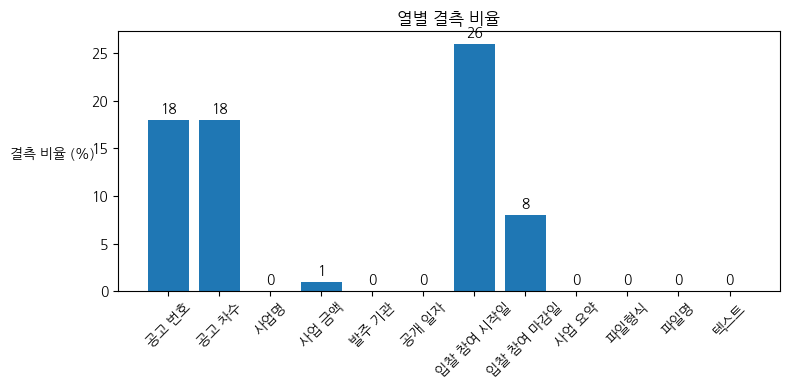

In [ ]:
missing = pd.DataFrame({
    "결측치 개수": df.isna().sum(),
    "결측 비율(%)": (df.isna().sum() / len(df) * 100).round(2)
})

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(missing.index, missing["결측 비율(%)"])

ax.bar_label(bars, labels=missing["결측치 개수"], padding=3)

ax.set_title("열별 결측 비율")
ax.set_ylabel("결측 비율 (%)", rotation=0, labelpad=28)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# 공고 번호
- missing value 18개
- duplicated 없음
- row: 7, 8, 24, 25, 27, 30, 31, 32, 33는 R25로 시작함
- 차세대 공고 번호임
- 모두 R25BK로 시작함 == 정상임
- https://m.blog.naver.com/jodalpower/223727858172

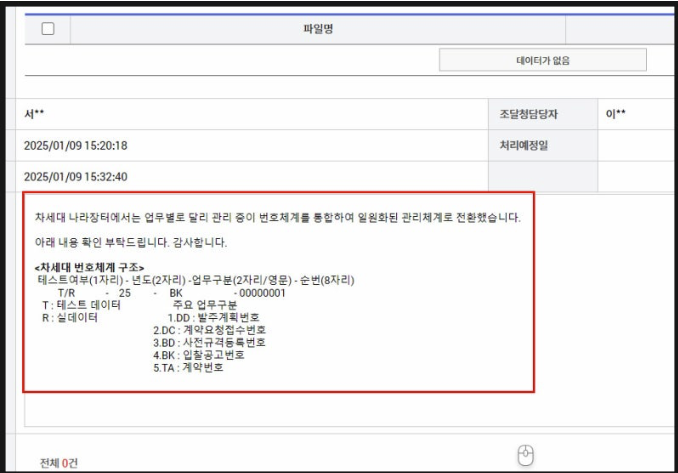


In [ ]:
df["공고 번호"].unique()

array(['20241001798', '20241002912', '20240827859', '20240430918',
       '20240430896', 'R25BK00559883', 'R25BK00564730', nan,
       '20240821865', '20240821893', '20240812818', '20240815487',
       '20240910050', '20240903676', '20240903688', '20240904268',
       'R25BK00632049', 'R25BK00632248', 'R25BK00601569', 'R25BK00603644',
       'R25BK00603533', 'R25BK00604826', 'R25BK00605617', '20240523741',
       '20240524568', '20240413838', '20240414353', '20240345257',
       '20241213403', '20240404154', '20241138828', '20241138864',
       '20241139040', '20240723270', '20240723668', '20241130016',
       '20241120435', '20241118572', '20240531013', '20240535775',
       '20240539319', '20240539643', '20240611568', '20240611774',
       '20240605067', '20240605351', '20240605366', '20241211469',
       '20241217596', '20241218257', '20240541684', '20240541779',
       '20241207733', '20240531285', '20240531160', '20240531542',
       '20241014232', '20241030067', '20241021784', '2

# 공고 차수
- missing value 18개
- 0차 1차 2차 있음 -> 문제 없음

In [ ]:
df['공고 차수'].unique()

array([ 0., nan,  1.,  2.])

In [ ]:
# 재공고인데 0차가 있는지
# 재공고인데 1차 혹은 2차여야함.
# 처음 올린 공고인데 2차인지
re_announcement_df = df[df['사업명'].str.contains("재공고", na=False)]
re_announcement_df

,공고 번호,공고 차수,사업명,사업 금액,발주 기관,공개 일자,입찰 참여 시작일,입찰 참여 마감일,사업 요약,파일형식,파일명,텍스트
44,20240723668,0.0,전문대학 혁신지원사업 서영대학교 차세대 교육혁신지원시스템 3단계 구축 용역 재공고,9.500000e+08,서영대학교 산학협력단,2024-07-18 15:12:16,2024-07-24 09:00:00,2024-07-29 14:00:00,- 사업 개요: 서영대학교 차세대 교육혁신지원시스템 3단계 구축 사업\n- 추진배경...,hwp,서영대학교 산학협력단_전문대학 혁신지원사업 서영대학교 차세대 교육.hwp,\r\n \r\n서영대학교 차세대 교육혁신지원시스템 3단계 구축 사업 제안요...
47,NaN,NaN,[재공고]차세대 통합정보시스템(ERP) 구축,1.410701e+10,한국가스공사,2024-08-08 00:00:00,NaN,2024-09-09 15:00:00,- 사업목적: 기술지원 종료에 대비한 ERP 업그레이드로 안정적 서비스 제공 및 업...,hwp,한국가스공사_[재공고]차세대 통합정보시스템(ERP) 구축.hwp,\r\n과 업 지 시 서\r\n- 차세대 통합정보시스템(ERP) 구축 -\r...
68,20240531160,0.0,"(재공고, 협상) 서울 디지털성범죄 안심지원센터 업무시스템 및 AI 기반 삭제지원시...",3.364030e+08,서울특별시 여성가족재단,2024-05-24 10:24:58,2024-05-24 14:00:00,2024-06-04 14:00:00,- 사업개요: 서울 디지털성범죄 안심지원센터 업무시스템 및 AI 기반 삭제지원 시스...,hwp,"서울특별시 여성가족재단_(재공고, 협상) 서울 디지털성범죄 안심지원센.hwp",\r\n제 안 요 청 서\r\n \r\n사 업 명\r\n서울 디지털성범죄 안...
71,NaN,NaN,[재공고][긴급][협상형]운행정보기록 자동분석시스템 개량,0.000000e+00,한국철도공사 (용역),2024-08-12 00:00:00,2024-08-21 00:00:00,2024-08-23 00:00:00,- 사업 개요: 운행정보기록 자동분석시스템 개량\n- 추진배경: 기존 시스템의 정합...,hwp,한국철도공사 (용역)_[재공고][긴급][협상형]운행정보기록 자동분석시스.hwp,\r\n \r\n \r\n제안요청서\r\n운행정보기록 자동분석시스템 개량 \r\...
79,20240624332,0.0,인천공항운영서비스㈜ 차세대 ERP시스템 구축 사업(재공고),1.095992e+09,인천공항운영서비스(주),2024-06-18 15:37:22,2024-06-18 17:00:00,2024-07-02 14:00:00,- 사업명: 인천공항운영서비스 차세대 ERP시스템 구축 사업\n- 사업기간: 9개월...,hwp,인천공항운영서비스(주)_인천공항운영서비스㈜ 차세대 ERP시스템 구축 .hwp,\r\n \r\n차세대 ERP시스템 구축 사업\r\n제 안 요 청 서\r\n20...
92,20241103380,0.0,(재공고)2024 조선대학교 SW중심대학 사업관리시스템(WeHub) 구축,1.000000e+08,조선대학교,2024-11-04 17:48:35,NaN,2024-11-20 12:30:00,- 사업 개요: 2024 조선대학교 SW중심대학 사업관리시스템(WeHub) 구축\n...,hwp,조선대학교_(재공고)2024 조선대학교 SW중심대학 사업관리시스템(WeHub) 구.hwp,제 안 요 청 서\r\n \r\n사 업 명\r\n2024 조선대학교 SW중심...
95,20240409322,0.0,적십자병원 병원정보 재해복구시스템 구축 용역 재공고입찰,5.000000e+08,대한적십자사 의료원,2024-04-04 16:55:56,2024-04-11 09:00:00,2024-04-15 11:00:00,- 사업개요: 적십자병원 병원정보 재해복구시스템 구축\n- 추진배경 및 필요성: 병...,hwp,대한적십자사 의료원_적십자병원 병원정보 재해복구시스템 구축 용역 .hwp,\r\n \r\n제안요청서\r\n \r\n사 업 명\r\n적십자병원 병원정보 재...
98,20240419765,0.0,2024년 광주문화예술통합플랫폼 시스템 유지 및 보수 용역 제안서 제출 안내 재공고,6.189000e+07,재단법인 광주광역시 광주문화재단,2024-04-12 10:16:47,NaN,2024-04-23 10:00:00,- 사업개요: 2024년 광주문화예술통합플랫폼 시스템 유지 및 보수 용역\n- 추진...,hwp,재단법인 광주광역시 광주문화재단_2024년 광주문화예술통합플랫폼 시스.hwp,\r\n제 안 요 청 서\r\n \r\n사 업 명\r\n2024년 광주문화...


# 사업 금액 확인
- 0인것: 6개
- NaN: 1개
``` text
사업 금액 (0 포함이라서 별 의미 없을 거 같긴한데)
count	9.900000e+01   원래 100개인데 NaN 1개사라짐
mean	6.906720e+08 6억 9천
std	1.966691e+09   19억 6천
min	0.000000e+00   0 원
25%	7.000000e+07   7천만
50%	1.727000e+08   1억 7천
75%	4.064889e+08   4억 600만
max	1.410701e+10   141억
```


In [ ]:
invalid_amount = df[(df["사업 금액"].isna()) | (df["사업 금액"] == 0)]

print(len(invalid_amount))
invalid_amount
#TODO 사업 금액 missing value 고치기

7


,공고 번호,공고 차수,사업명,사업 금액,발주 기관,공개 일자,입찰 참여 시작일,입찰 참여 마감일,사업 요약,파일형식,파일명,텍스트
12,NaN,NaN,[사전공개] 학업성취도 다차원 종단분석 통합시스템 1차 고도화 용역,0.0,서울시립대학교,2023-06-20 00:00:00,NaN,NaN,- 사업개요: 학업성취도 다차원 종단분석 통합시스템 1차 고도화\n- 추진배경: 서...,pdf,서울시립대학교_[사전공개] 학업성취도 다차원 종단분석 통합시스템 1차.pdf,[사전공개용]\n제 안 요 청 서\n\n사 업 명\n\n학업성취도 다차원...
13,NaN,NaN,[입찰공고] 산학협력단 정보시스템 운영 용역업체 선정,0.0,경희대학교,2024-05-02 00:00:00,NaN,NaN,- 사업명: 경희대학교 산학협력단 정보시스템 운영 용역사업\n- 추진배경: 정보시스...,hwp,경희대학교_[입찰공고] 산학협력단 정보시스템 운영 용역업체 선정.hwp,\r\n \r\n 제안요청서\r\n제안서\r\n \r\n경희대학교 산학협력단...
16,NaN,NaN,예약발매시스템 개량 ISMP 용역,0.0,한국철도공사 (용역),2024-05-31 00:00:00,2024-06-07 00:00:00,2024-06-11 00:00:00,- 사업 개요: 예약발매시스템 개량을 위한 업무 종합계획(ISMP) 수립\n- 추진...,hwp,한국철도공사 (용역)_예약발매시스템 개량 ISMP 용역.hwp,\r\n \r\n \r\n제안요청서\r\n예약발매시스템 개량 ISMP 용역\...
34,NaN,NaN,모바일오피스 시스템 고도화 용역(총체 및 1차),0.0,한국철도공사 (용역),2024-10-11 00:00:00,2024-10-18 00:00:00,2024-10-22 00:00:00,- 사업 개요: 모바일오피스 시스템 고도화를 통해 모바일 업무지원 확대 및 서비스 ...,hwp,한국철도공사 (용역)_모바일오피스 시스템 고도화 용역(총체 및 1차).hwp,\r\n \r\n제안요청서\r\n모바일오피스 시스템 고도화\r\n \r\n202...
41,20241138864,0.0,을지대학교 비교과시스템 개발,0.0,을지대학교,2024-11-27 10:51:02,NaN,2024-12-05 17:00:00,- 사업 개요: 을지대학교 비교과시스템 및 교육과정인증 관리 시스템 구축\n- 추진...,hwp,을지대학교_을지대학교 비교과시스템 개발.hwp,\r\n \r\n을지대학교 \r\n비교과시스템 개발사업 제안요청서\r\n \r...
59,20240605351,0.0,기업 재생에너지 지원센터 홈페이지 개편 및 시스템 고도화 사업,NaN,대한상공회의소,2024-06-05 11:12:09,NaN,2024-06-14 14:00:00,- 기업 재생에너지 지원센터 홈페이지 개편 및 시스템 고도화 사업\n- 재생에너지 ...,hwp,대한상공회의소_기업 재생에너지 지원센터 홈페이지 개편 및 시스템 고.hwp,\r\n\t신 - \t\r\n \r\n \r\n기업 재생에너지 지원센터 ...
71,NaN,NaN,[재공고][긴급][협상형]운행정보기록 자동분석시스템 개량,0.0,한국철도공사 (용역),2024-08-12 00:00:00,2024-08-21 00:00:00,2024-08-23 00:00:00,- 사업 개요: 운행정보기록 자동분석시스템 개량\n- 추진배경: 기존 시스템의 정합...,hwp,한국철도공사 (용역)_[재공고][긴급][협상형]운행정보기록 자동분석시스.hwp,\r\n \r\n \r\n제안요청서\r\n운행정보기록 자동분석시스템 개량 \r\...


In [ ]:
df["사업 금액"].describe()


,사업 금액
count,9.900000e+01
mean,6.906720e+08
std,1.966691e+09
min,0.000000e+00
25%,7.000000e+07
50%,1.727000e+08
75%,4.064889e+08
max,1.410701e+10


# 발주 기관
- 총 87곳임

In [ ]:
print("발주 기관의 총 개수:",len(df["발주 기관"].unique()))
print(df["발주 기관"].unique())

발주 기관의 총 개수: 87
['한영대학' '한국연구재단' '한국생산기술연구원' '인천광역시' '경상북도 봉화군' '한국전기안전공사' '재단법인충북연구원'
 '고려대학교' '재단법인스포츠윤리센터' '국방과학연구소' '(사）한국대학스포츠협의회' '한국사학진흥재단' '서울시립대학교'
 '경희대학교' '한국수자원공사' '국가과학기술지식정보서비스' '한국철도공사 (용역)'
 '2025 구미 아시아육상경기선수권대회 조직위원회' '한국발명진흥회 입찰공고' '고양도시관리공사' '전북대학교'
 '한국보건산업진흥원' '한국사회보장정보원' '수협중앙회' '한국농어촌공사' 'KOICA 전자조달' '대한장애인체육회'
 '인천광역시 동구' '축산물품질평가원' '울산광역시' '한국재정정보원' '부산관광공사' '전북특별자치도 정읍시' '광주과학기술원'
 '서울특별시' '재단법인경기도일자리재단' '을지대학교' '대전대학교' '서영대학교 산학협력단' '한국농수산식품유통공사'
 'BioIN' '한국가스공사' '국민연금공단' '기초과학연구원' '중앙선거관리위원회' '대검찰청' '한국한의학연구원'
 '한국어촌어항공단' '서민금융진흥원' '(사)부산국제영화제' '대한상공회의소' '경기도 평택시' '케빈랩 주식회사'
 '한국로봇산업진흥원' '한국건강가정진흥원' '파주도시관광공사' '국립인천해양박물관' '한국교육과정평가원' '서울특별시 여성가족재단'
 '국립중앙의료원' '국가철도공단' '사단법인아시아물위원회사무국' '재단법인 광주연구원' '경기도 안양시' '남서울대학교'
 '한국지식재산보호원' '인천공항운영서비스(주)' '한국산업인력공단' '한국원자력연구원' '한국해양조사협회' '사단법인 보험개발원'
 '서울특별시교육청' '재단법인 한국장애인문화예술원' '(사)벤처기업협회' '경기도사회서비스원' '세종테크노파크' '한국수출입은행'
 '문화체육관광부 국립민속박물관' '한국보육진흥원' '조선대학교' '그랜드코리아레저(주)' '한국산업단지공단' '대한적십자사 의료원'
 '한국수자원조사기술원' '(재)예술경

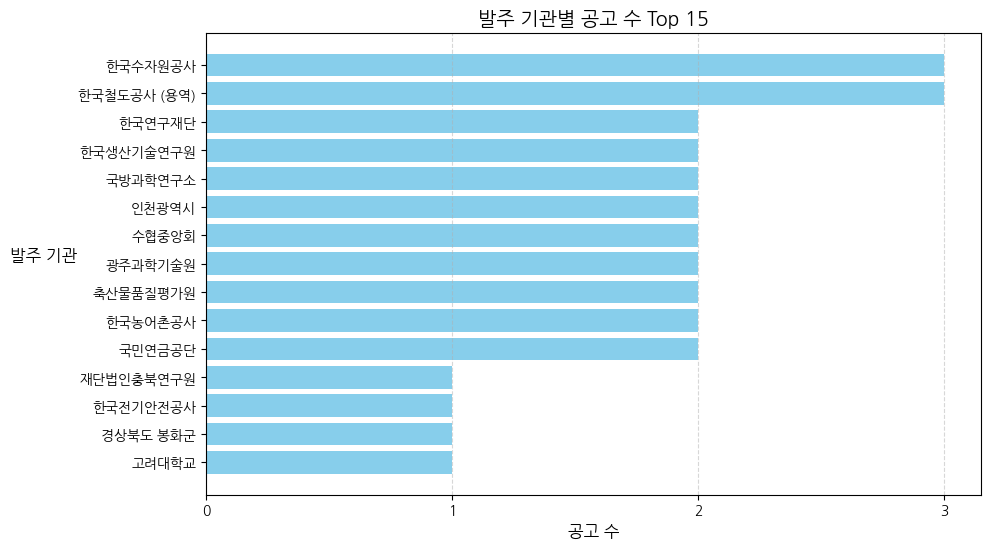

In [ ]:
top15 = df["발주 기관"].value_counts().head(15)

plt.figure(figsize=(10, 6))
plt.barh(top15.index, top15.values, color='skyblue')
plt.xlabel("공고 수", fontsize=12)
plt.ylabel("발주 기관", fontsize=12, rotation = 0, labelpad = 25)
plt.xticks(np.arange(0, top15.max() + 1, 1))
plt.title("발주 기관별 공고 수 Top 15", fontsize=14)
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.show()

# 공개 일자
- 일단 데이트타임 형식

In [ ]:
df[["공개 일자", "입찰 참여 시작일", "입찰 참여 마감일"]].dtypes

,0
공개 일자,object
입찰 참여 시작일,object
입찰 참여 마감일,object


## 전체 기간 확인
- 21년 23년 24년 25년 있음

In [ ]:
sorted_dates = np.sort(df['공개 일자'].unique())
sorted_dates

array(['2021-10-08 00:00:00', '2023-06-20 00:00:00',
       '2024-02-13 00:00:00', '2024-03-19 09:18:41',
       '2024-03-19 10:49:46', '2024-03-19 13:47:26',
       '2024-03-19 17:42:23', '2024-04-02 15:19:35',
       '2024-04-02 15:49:39', '2024-04-04 14:17:16',
       '2024-04-04 15:09:35', '2024-04-04 16:55:56',
       '2024-04-04 18:31:59', '2024-04-08 17:08:33',
       '2024-04-08 18:24:26', '2024-04-12 09:38:55',
       '2024-04-12 10:16:47', '2024-04-12 11:18:21',
       '2024-04-18 10:59:30', '2024-04-18 16:26:32',
       '2024-04-18 16:33:28', '2024-04-30 11:27:29',
       '2024-05-02 00:00:00', '2024-05-07 00:00:00',
       '2024-05-13 00:00:00', '2024-05-20 14:07:02',
       '2024-05-20 17:23:27', '2024-05-24 09:47:11',
       '2024-05-24 10:24:58', '2024-05-24 11:09:47',
       '2024-05-30 00:00:00', '2024-05-30 09:04:12',
       '2024-05-30 09:29:26', '2024-05-30 10:20:19',
       '2024-05-30 11:00:23', '2024-05-31 00:00:00',
       '2024-05-31 13:21:40', '2024-05-31 13:5

## 21년, 23년 데이터 확인
- 21, 23년은 좀 오래된 거 같아서 확인
- 별로 이상한 건 없음

In [ ]:
df["공개 일자"] = pd.to_datetime(df["공개 일자"], errors="coerce")
target = pd.concat([
    df[df["공개 일자"] == "2023-06-20"],
    df[df["공개 일자"].dt.year == 2021]
])

target

,공고 번호,공고 차수,사업명,사업 금액,발주 기관,공개 일자,입찰 참여 시작일,입찰 참여 마감일,사업 요약,파일형식,파일명,텍스트
12,NaN,NaN,[사전공개] 학업성취도 다차원 종단분석 통합시스템 1차 고도화 용역,0.0,서울시립대학교,2023-06-20,NaN,NaN,- 사업개요: 학업성취도 다차원 종단분석 통합시스템 1차 고도화\n- 추진배경: 서...,pdf,서울시립대학교_[사전공개] 학업성취도 다차원 종단분석 통합시스템 1차.pdf,[사전공개용]\n제 안 요 청 서\n\n사 업 명\n\n학업성취도 다차원...
88,NaN,NaN,세종테크노파크 인사정보 전산시스템 구축 용역 입찰공고[긴급],90000000.0,세종테크노파크,2021-10-08,NaN,NaN,- 사업개요: 세종테크노파크 인사정보 전산시스템 구축\n- 추진배경: 인사정보관리의...,hwp,세종테크노파크_세종테크노파크 인사정보 전산시스템 구축 용역 입찰공.hwp,\r\n \r\n \r\n 인사정보 전산시스템 구축 용역 \r\n제 안 ...


## 공개-시작, 시작-마감 integrity 확인
- 양쪽 모두 기간이 매우 짧은 건 있지만, 시간이 역순으로 돌아가는 것은 없음


In [ ]:
import pandas as pd

# --- 안전한 차이 계산용 컬럼 생성 ---
df.loc[:, "공개→시작 차이"] = df["입찰 참여 시작일"] - df["공개 일자"]
df.loc[:, "시작→마감 차이"] = df["입찰 참여 마감일"] - df["입찰 참여 시작일"]


# --- ① 공개일자 > 입찰 시작일 ---
invalid_start = df[df["공개 일자"] > df["입찰 참여 시작일"]]

# --- ② 공개일자 > 입찰 마감일 ---
invalid_end = df[df["공개 일자"] > df["입찰 참여 마감일"]]

# --- ③ 공개일자~입찰 시작일 간격 < 1일 ---
short_notice = df[df["공개→시작 차이"] < pd.Timedelta(days=1)]

# --- ④ 입찰 시작일~마감일 간격 < 1일 ---
short_bid = df[df["시작→마감 차이"] < pd.Timedelta(days=1)]

# --- ⑤ 입찰 시작일 > 마감일 ---
invalid_order = df[df["입찰 참여 시작일"] > df["입찰 참여 마감일"]]


# --- 출력 ---
print("📌 (1) 공개일자가 입찰 시작일보다 늦은 행")
display(invalid_start)

print("📌 (2) 공개일자가 입찰 마감일보다 늦은 행")
display(invalid_end)

print("📌 (3) 공개일자~입찰 시작일 사이가 1일 미만인 행")
display(short_notice)

TypeError: cannot subtract DatetimeArray from ndarray

- 전기안전 관제시스템 보안 모듈 개발 용역: 수의 계약
- 아태 사이버범죄 역량강화 허브(APC-HUB) 홈페이지 및 온라인 교육시: 수의 게약
- 한국어촌어항공단 경영관리시스템(ERP·GW) 기능 고도화 용역: 수의 계약
- 2세대 전자조달시스템 기반구축사업: 수의계약
- 한국로봇산업진흥원 사업관리시스템 온라인평가 체계 구축: 수의 계약
- 네팔 수자원관리 정보화사업-Pilot 시스템 구축용역: 수의 계약
## 전부 수의 계약임


In [ ]:
print("📌 (4) 입찰 시작일~마감일 사이가 1일 미만인 행")
display(short_bid)

print("📌 (5) 입찰 시작일이 마감일보다 늦은 행")
display(invalid_order)

## 입찰 공개 -> 입찰 시작 시각화

In [ ]:
values = df["공개→시작 차이"].dt.days.dropna()

fig, ax1 = plt.subplots(figsize=(10,5))

# --- 히스토그램 ---
sns.histplot(values, bins=20, ax=ax1, color="skyblue", alpha=0.6)
ax1.set_xlabel("일(day)")

# 🔽 y축 라벨을 살짝 아래로 이동
ax1.set_ylabel("Count", rotation=0, labelpad=20)
ax1.yaxis.set_label_coords(-0.05, 0.45)   # ← 왼쪽/아래 이동

ax1.grid(axis='y', alpha=0.3)

# x축 범위
max_day = int(values.max())
ax1.set_xlim(1, max_day)

# ticks 설정
ticks_1 = list(range(1, 11, 3))
ticks_2 = list(range(15, max_day+1, 5))
ax1.set_xticks(ticks_1 + ticks_2)

# --- KDE ---
ax2 = ax1.twinx()
sns.kdeplot(values, ax=ax2, color="red", linewidth=2)

# 🔽 오른쪽 y축 라벨도 아래로 이동
ax2.set_ylabel("Density", rotation=0, labelpad=20)
ax2.yaxis.set_label_coords(1.05, 0.45)

plt.title("공개일자 → 입찰 시작일까지의 기간 분포 (히스토그램 + KDE)")
plt.show()

## 입찰 시작 -> 입찰 마감 사이의 기간 시각화

In [ ]:
values = df["시작→마감 차이"].dt.days.dropna()

fig, ax1 = plt.subplots(figsize=(10, 5))

# --- 히스토그램 (왼쪽 y축) ---
sns.histplot(values, bins=30, ax=ax1, color="skyblue", alpha=0.6)
ax1.set_xlabel("일(day)")
ax1.set_ylabel("Count", rotation=0, labelpad=20)
ax1.grid(axis='y', alpha=0.4)

# --- x축 범위 지정 (음수 제거) ---
max_day = int(values.max())
ax1.set_xlim(-1, max_day)

# --- x축 ticks 설정 ---
ticks_1 = list(range(1, 16, 3))     # 1,4,7,10,13
ticks_2 = list(range(20, max_day+1, 5))
ax1.set_xticks(ticks_1 + ticks_2)

# --- KDE (오른쪽 y축) ---
ax2 = ax1.twinx()
sns.kdeplot(values, ax=ax2, color="red", linewidth=2)

ax2.set_ylabel("Density", rotation=0, labelpad=20)
ax2.yaxis.set_label_coords(1.05, 0.45)
plt.title("입찰 시작일 → 입찰 마감일까지의 기간 분포 (히스토그램 + KDE)", fontsize=14)
plt.show()

# 사업명
- 중복 값이 1개 있음. 15행(국가과학기술지식정보서비스) 53행(한국한의학연구원)
- 17행을 지우기

In [ ]:
print(len(df['사업명'].unique()))
(df["사업명"].value_counts()[df["사업명"].value_counts() > 1])

In [ ]:
duplicated_titles = df["사업명"].value_counts()[df["사업명"].value_counts() > 1].index

df[df["사업명"].isin(duplicated_titles)]
# 나중에 삭제하기
# df = df[~((df["사업명"] == "통합정보시스템 고도화 용역") & (df["발주기관"] == "국가과학기술지식정보서비스"))]

# 파일 형식

In [ ]:
file_counts = df["파일형식"].value_counts()

plt.figure(figsize=(5,5))
plt.title("파일형식 분포 (Pie Chart)", fontsize=18)

wedges, texts, autotexts = plt.pie(
    file_counts,
    labels=file_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    textprops={"fontsize": 14},
)

for autotext in autotexts:
    autotext.set_fontsize(14)

plt.show()

print(df["파일형식"].value_counts())

# 파일명
- 유니크 값이 100개임 -> 중복 없음

In [ ]:
print(len(df['파일명'].unique()))
df['파일명'].unique()

# 텍스트 확인
- NULL or 공백만 있는 것은 없음

In [ ]:
(df["텍스트"].isna() | (df["텍스트"].str.strip() == "")).sum()

## 길이가 큰 의미는 없을 거 같지만 일단 확인...

In [ ]:
text_lengths = df['텍스트'].str.len()
print(text_lengths.describe())

In [ ]:
a = df['텍스트'].str.len() == 89
df[a]
# 2024년 건설기술에 관한 특허-실용신안 활용실적 관리시스템 개편 용역 제안요청서
# 2024. 4.


# 기업성장지원실

# 부서명

# 이딴게 요약인가

In [ ]:
text_lengths = df['텍스트'].str.len()

plt.figure(figsize=(10, 5))
sns.histplot(text_lengths, bins=20, kde=True)

plt.title("텍스트 길이 분포")
plt.xlabel("글자 수")
plt.ylabel("빈도수")
plt.grid(True)
plt.show()

In [ ]:
df.head()

,공고 번호,공고 차수,사업명,사업 금액,발주 기관,공개 일자,입찰 참여 시작일,입찰 참여 마감일,사업 요약,파일형식,파일명,텍스트
0,20241001798,0.0,한영대학교 특성화 맞춤형 교육환경 구축 - 트랙운영 학사정보시스템 고도화,130000000.0,한영대학,2024-10-04 13:51:23,NaN,2024-10-15 17:00:00,- 한영대학교 특성화 맞춤형 교육환경 구축을 위해 트랙운영 학사정보시스템을 고도화한...,hwp,한영대학_한영대학교 특성화 맞춤형 교육환경 구축 - 트랙운영 학사정보.hwp,\n \n2024년 특성화 맞춤형 교육환경 구축 – 트랙운영 학사정보시스템 ...
1,20241002912,0.0,2024년 대학산학협력활동 실태조사 시스템(UICC) 기능개선,129300000.0,한국연구재단,2024-10-04 15:01:52,2024-10-14 10:00:00,2024-10-16 14:00:00,- 사업 개요: 2024년 대학 산학협력활동 실태조사 시스템(UICC) 기능개선\n...,hwp,한국연구재단_2024년 대학산학협력활동 실태조사 시스템(UICC) 기능개선.hwp,\r\n \r\n \r\n \r\n제 안 요 청 서\r\n[ 2024년 대학 ...
2,20240827859,0.0,EIP3.0 고압가스 안전관리 시스템 구축 용역,40000000.0,한국생산기술연구원,2024-08-28 11:31:02,2024-08-29 09:00:00,2024-09-09 10:00:00,- 사업 개요: EIP3.0 고압가스 안전관리 시스템 구축 용역\n- 추진배경: 안...,hwp,한국생산기술연구원_EIP3.0 고압가스 안전관리 시스템 구축 용역.hwp,\r\n \r\nEIP3.0 고압가스 안전관리\r\n시스템 구축 용역\...
3,20240430918,0.0,도시계획위원회 통합관리시스템 구축용역,150000000.0,인천광역시,2024-04-18 16:26:32,2024-05-02 10:00:00,2024-05-09 16:00:00,- 사업명: 도시계획위원회 통합관리시스템 구축 용역\n- 용역개요: 도시계획위원회와...,hwp,인천광역시_도시계획위원회 통합관리시스템 구축용역.hwp,\r\n \r\n \r\n도시계획위원회 통합관리시스템 구축\r\n제 안 요 청...
4,20240430896,0.0,봉화군 재난통합관리시스템 고도화 사업(협상)(긴급),900000000.0,경상북도 봉화군,2024-04-18 16:33:28,2024-04-26 09:00:00,2024-04-30 17:00:00,- 사업명: 봉화군 재난통합관리시스템 고도화 사업\n- 사업개요: 공동수급(공동이행...,hwp,경상북도 봉화군_봉화군 재난통합관리시스템 고도화 사업(협상)(긴급).hwp,\r\n \r\n \r\n제안요청서\r\n \r\n사 업 명\r\n봉화...


# CLOVA, Llama Parse
- 먼저 클로바부터

In [ ]:
import requests
import uuid
import time
import json
a ="/content/drive/MyDrive/원본데이터(공고명+사업명) 수정본_v2/proj_009/재단법인스포츠윤리센터_스포츠윤리센터 LMS(학습지원시스템) 기능개선.pdf"
api_url = 'https://4txlxeq8jy.apigw.ntruss.com/custom/v1/48738/30c471f6aafbca7085640653eeef555e85eb0df1602c98a662814c27767d1188/general'
secret_key = 'QURtVGh5QlBZSENXcElUc0ZhaEZ5cWdUUnpyY3VHc2w='


headers = {
    'X-OCR-SECRET': secret_key
}

payload = {
    'images': [{
        'format': 'pdf',
        'name': 'sample'
    }],
    'requestId': str(uuid.uuid4()),
    'version': 'V1',
    'timestamp': int(time.time() * 1000)
}

files = {
    'message': (None, json.dumps(payload), 'application/json'),
    'file': open(a, 'rb')
}

response = requests.post(api_url, headers=headers, files=files)

if response.status_code == 200:
    result = response.json()
    texts = [field["inferText"] for field in result["images"][0]["fields"]]
    text_output = " ".join(texts)
    print(text_output)
else:
    print(f"❌ Error {response.status_code}")
    print(response.text)

❌ Error 400
{"code":"0011","message":"Request invalid: No more than 10 pages.","path":"/external/v1/48738/30c471f6aafbca7085640653eeef555e85eb0df1602c98a662814c27767d1188/general","traceId":"e34996d7be2043a1b0a83c67224f48d3","timestamp":1765863217071}


In [ ]:
import fitz
import requests
import json
import uuid
import time
import numpy as np
from sklearn.cluster import KMeans


API_URL = 'https://4txlxeq8jy.apigw.ntruss.com/custom/v1/48738/30c471f6aafbca7085640653eeef555e85eb0df1602c98a662814c27767d1188/general'
SECRET_KEY = 'QURtVGh5QlBZSENXcElUc0ZhaEZ5cWdUUnpyY3VHc2w='
PDF_PATH = "/content/drive/MyDrive/원본데이터(공고명+사업명) 수정본_v2/proj_056/(사)부산국제영화제_2024년 BIFF & ACFM 온라인서비스 재개발 및 행사지원시.pdf"
MAX_PAGES = 10
OUTPUT_MD = "ocr_output44.md"
# =========================
# CLOVA OCR 호출
# =========================
def call_clova_ocr(pdf_bytes):
    payload = {
        "images": [{"format": "pdf", "name": "sample"}],
        "requestId": str(uuid.uuid4()),
        "version": "V1",
        "timestamp": int(time.time() * 1000)
    }

    files = {
        "message": (None, json.dumps(payload), "application/json"),
        "file": ("temp.pdf", pdf_bytes, "application/pdf")
    }

    headers = {"X-OCR-SECRET": SECRET_KEY}

    r = requests.post(API_URL, headers=headers, files=files)
    r.raise_for_status()
    return r.json()
def reconstruct_lines(items):
    if not items:
        return []

    items = sorted(items)  # (y, x, text)
    ys = [y for y, _, _ in items]
    text_h = max(ys) - min(ys) or 1.0

    y_th = text_h * 0.015
    block_gap = text_h * 0.06

    blocks, cur = [], [items[0]]
    for prev, curr in zip(items, items[1:]):
        if curr[0] - prev[0] > block_gap:
            blocks.append(cur)
            cur = [curr]
        else:
            cur.append(curr)
    blocks.append(cur)

    lines = []
    for block in blocks:
        line, last_y = [], None
        for y, x, text in block:
            if last_y is None or abs(y - last_y) < y_th:
                line.append((x, text))
                last_y = y
            else:
                line.sort()
                lines.append(" ".join(t for _, t in line))
                line = [(x, text)]
                last_y = y
        if line:
            line.sort()
            lines.append(" ".join(t for _, t in line))
        lines.append("")
    return lines[:-1]

# =========================
# 컬럼 수 판별 (1단 / 2단)
# =========================
def detect_columns(fields, page_width):
    xs = []

    for f in fields:
        verts = f["boundingPoly"]["vertices"]
        x_avg = sum(v["x"] for v in verts) / 4
        xs.append(x_avg / page_width)

    if len(xs) < 15:
        return 1

    xs = np.array(xs).reshape(-1, 1)
    kmeans = KMeans(n_clusters=2, n_init=10).fit(xs)
    centers = sorted(c[0] for c in kmeans.cluster_centers_)

    if abs(centers[1] - centers[0]) > 0.25:
        return 2
    return 1

# =========================
# 줄 복원 (2단)
# =========================
def reconstruct_lines_two_columns(fields, page_width, y_threshold=10):
    left, right = [], []
    mid_x = page_width / 2

    for f in fields:
        text = f["inferText"]
        verts = f["boundingPoly"]["vertices"]
        x = sum(v["x"] for v in verts) / 4
        y = sum(v["y"] for v in verts) / 4

        if x < mid_x:
            left.append((y, x, text))
        else:
            right.append((y, x, text))

    def build(items):
        items.sort()
        lines = []
        current_y = None
        current_line = []

        for y, x, text in items:
            if current_y is None or abs(y - current_y) < y_threshold:
                current_line.append((x, text))
                current_y = y
            else:
                current_line.sort()
                lines.append(" ".join(t for _, t in current_line))
                current_line = [(x, text)]
                current_y = y

        if current_line:
            current_line.sort()
            lines.append(" ".join(t for _, t in current_line))

        return lines

    return build(left) + [""] + build(right)

# =========================
# 메인 OCR 파이프라인
# =========================
def ocr_to_markdown():
    doc = fitz.open(PDF_PATH)
    page_count = min(doc.page_count, MAX_PAGES)

    temp = fitz.open()
    temp.insert_pdf(doc, from_page=0, to_page=page_count - 1)
    pdf_bytes = temp.tobytes()
    temp.close()

    result = call_clova_ocr(pdf_bytes)

    md = []
    md.append("# OCR 결과\n")

    for img in result["images"]:
        page_idx = img.get("pageIndex", 0)
        page = page_idx + 1

        # ✅ PDF에서 page width 직접 가져오기
        page_rect = doc[page_idx].rect
        page_width = page_rect.width

        fields = img["fields"]

        md.append(f"## Page {page}\n")

        col_count = detect_columns(fields, page_width)

        if col_count == 1:
            lines = reconstruct_lines(fields)
        else:
            lines = reconstruct_lines_two_columns(fields, page_width)

        md.extend(lines)
        md.append("")

    doc.close()

    with open(OUTPUT_MD, "w", encoding="utf-8") as f:
        f.write("\n".join(md))

    print(f"✅ OCR + 문맥 복원 완료 → {OUTPUT_MD}")

# =========================
# 실행
# =========================
if __name__ == "__main__":
    ocr_to_markdown()

KeyboardInterrupt: 

In [ ]:
import os
import fitz
import requests
import json
import uuid
import time
import numpy as np
from sklearn.cluster import KMeans
from pathlib import Path

# =========================
# 설정
# =========================
PDF_PATH = "/content/drive/MyDrive/최종_파싱용_데이터_Perfect/proj_060/케빈랩 주식회사_평택시 강소형 스마트시티 AI 기반의 영상감시 시스템 .pdf"
OUTPUT_MD = "single_test.md"

MAX_PAGES = 10        # ⭐ 앞에서부터 10페이지만
SLEEP_SEC = 0.2

# =========================
# CLOVA OCR
# =========================
def call_clova_ocr(pdf_bytes):
    payload = {
        "images": [{"format": "pdf", "name": "sample"}],
        "requestId": str(uuid.uuid4()),
        "version": "V1",
        "timestamp": int(time.time() * 1000),
    }

    files = {
        "message": (None, json.dumps(payload), "application/json"),
        "file": ("temp.pdf", pdf_bytes, "application/pdf"),
    }

    headers = {"X-OCR-SECRET": SECRET_KEY}
    r = requests.post(API_URL, headers=headers, files=files)
    r.raise_for_status()
    return r.json()

# =========================
# OCR field → (y, x, text)
# =========================
def fields_to_items(fields):
    items = []
    for f in fields:
        verts = f["boundingPoly"]["vertices"]
        x = sum(v["x"] for v in verts) / 4
        y = sum(v["y"] for v in verts) / 4
        items.append((y, x, f["inferText"]))
    return items

# =========================
# 줄 복원 (스케일 정규화)
# =========================
def reconstruct_lines(items):
    if not items:
        return []

    items = sorted(items)
    ys = [y for y, _, _ in items]
    text_h = max(ys) - min(ys) or 1.0

    y_th = text_h * 0.015
    block_gap = text_h * 0.06

    blocks, cur = [], [items[0]]
    for prev, curr in zip(items, items[1:]):
        if curr[0] - prev[0] > block_gap:
            blocks.append(cur)
            cur = [curr]
        else:
            cur.append(curr)
    blocks.append(cur)

    lines = []
    for block in blocks:
        line, last_y = [], None
        for y, x, text in block:
            if last_y is None or abs(y - last_y) < y_th:
                line.append((x, text))
                last_y = y
            else:
                line.sort()
                lines.append(" ".join(t for _, t in line))
                line = [(x, text)]
                last_y = y
        if line:
            line.sort()
            lines.append(" ".join(t for _, t in line))
        lines.append("")
    return lines[:-1]

# =========================
# 목차 감지
# =========================
def is_toc_page(fields):
    joined = " ".join(f["inferText"] for f in fields)
    return ("목차" in joined) and (joined.count("·") + joined.count(".") > 20)

# =========================
# 블록 구조 판별 (1 vs 4)
# =========================
def detect_block_structure(items):
    xs = np.array([x for _, x, _ in items]).reshape(-1, 1)
    ys = np.array([y for y, _, _ in items]).reshape(-1, 1)

    def cnt(arr):
        if len(arr) < 20:
            return 1
        km = KMeans(n_clusters=2, n_init=10).fit(arr)
        return 2 if abs(km.cluster_centers_[0] - km.cluster_centers_[1]) > (arr.max() - arr.min()) * 0.25 else 1

    return cnt(xs), cnt(ys)

# =========================
# 단일 PDF 처리
# =========================
def process_single_pdf():
    doc = fitz.open(PDF_PATH)

    # ⭐ 앞에서부터 MAX_PAGES 페이지만 OCR
    temp = fitz.open()
    temp.insert_pdf(doc, from_page=0, to_page=min(MAX_PAGES, doc.page_count) - 1)
    pdf_bytes = temp.tobytes()
    temp.close()

    result = call_clova_ocr(pdf_bytes)

    md = [f"# OCR 결과\n\n## FILE: {Path(PDF_PATH).name}\n"]

    for img in result["images"]:
        page_idx = img.get("pageIndex", 0)
        fields = img.get("fields", [])
        items = fields_to_items(fields)

        md.append(f"\n## Page {page_idx + 1}\n")

        if is_toc_page(fields):
            md.extend(reconstruct_lines(items))
        else:
            x_cnt, y_cnt = detect_block_structure(items)

            # 4분면
            if x_cnt == 2 and y_cnt == 2:
                mx = np.mean([x for _, x, _ in items])
                my = np.mean([y for y, _, _ in items])

                blocks = [
                    [i for i in items if i[1] < mx and i[0] < my],
                    [i for i in items if i[1] >= mx and i[0] < my],
                    [i for i in items if i[1] < mx and i[0] >= my],
                    [i for i in items if i[1] >= mx and i[0] >= my],
                ]

                for b in blocks:
                    if b:
                        md.extend(reconstruct_lines(b))
                        md.append("")
            else:
                # 단일 흐름
                md.extend(reconstruct_lines(items))

        time.sleep(SLEEP_SEC)

    doc.close()

    with open(OUTPUT_MD, "w", encoding="utf-8") as f:
        f.write("\n".join(md))

    print(f"✅ 완료: {OUTPUT_MD}")

# =========================
# 실행
# =========================
if __name__ == "__main__":
    process_single_pdf()

✅ 완료: single_test.md


# 케빈 만족

In [ ]:
!pip install pymupdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.1/24.1 MB 82.4 MB/s eta 0:00:00


In [ ]:
import fitz
import requests
import json
import uuid
import time
import numpy as np
from sklearn.cluster import KMeans

# =========================
# 설정 (Settings)
# =========================
API_URL = "https://4txlxeq8jy.apigw.ntruss.com/custom/v1/48738/30c471f6aafbca7085640653eeef555e85eb0df1602c98a662814c27767d1188/general"
SECRET_KEY = 'QURtVGh5QlBZSENXcElUc0ZhaEZ5cWdUUnpyY3VHc2w='
# PDF_PATH = "/content/drive/MyDrive/최종_파싱용_데이터_Perfect/proj_060/20241211469-02_1733818400168_공고문_평택시 강소형 스마트시티 조성사업 영상 AI감지 및 홍수감시 연동시스템 구축사업.pdf"
# PDF_PATH = "/content/drive/MyDrive/최종_파싱용_데이터_Perfect/proj_060/케빈랩 주식회사_평택시 강소형 스마트시티 AI 기반의 영상감시 시스템 .pdf"
# PDF_PATH = "/content/drive/MyDrive/최종_파싱용_데이터_Perfect/proj_002/20241002912-00_1728021605690_입찰공고문_2024년 대학 산학협력활동 실태조사 시스템(UICC) 기능개선.pdf"
PDF_PATH = "/content/drive/MyDrive/최종_파싱용_데이터_Perfect/proj_066/20240531285-00_1716510986246_입찰공고문.pdf"
OUTPUT_MD = "ocr_output_auto_flowk66.md"
MAX_PAGES = 10  # PDF에서 처리할 페이지 수 (pages)
SLEEP_SEC = 0.2  # API 호출 간격 (rate limit 대비)

# =========================
# CLOVA OCR 호출 (Call)
# =========================
def call_clova_ocr(pdf_bytes: bytes) -> dict:
    payload = {
        "images": [{"format": "pdf", "name": "sample"}],
        "requestId": str(uuid.uuid4()),
        "version": "V1",
        "timestamp": int(time.time() * 1000),
    }

    files = {
        "message": (None, json.dumps(payload), "application/json"),
        "file": ("temp.pdf", pdf_bytes, "application/pdf"),
    }

    headers = {"X-OCR-SECRET": SECRET_KEY}

    r = requests.post(API_URL, headers=headers, files=files)
    r.raise_for_status()
    return r.json()

# =========================
# 유틸: OCR field -> (y,x,text)
# =========================
def fields_to_items(fields):
    items = []
    for f in fields:
        verts = f["boundingPoly"]["vertices"]
        x = sum(v["x"] for v in verts) / 4
        y = sum(v["y"] for v in verts) / 4
        items.append((y, x, f["inferText"]))
    return items

# =========================
# 1단/블록 안정 줄복원 (Scale-normalized line reconstruction)
# =========================
def reconstruct_lines_normalized_from_items(items):
    if not items:
        return []

    # y 기준 정렬
    items = sorted(items)

    ys = [y for y, _, _ in items]
    text_h = max(ys) - min(ys)
    if text_h <= 0:
        text_h = 1.0

    # ✅ 텍스트 영역 높이에 비례해서 임계값 자동 조절
    y_threshold = text_h * 0.015   # 같은 줄 판단
    block_gap = text_h * 0.06      # 블록 분리(문단 간 큰 공백)

    # 1) 블록 분리
    blocks = []
    cur = [items[0]]
    for prev, curr in zip(items, items[1:]):
        if (curr[0] - prev[0]) > block_gap:
            blocks.append(cur)
            cur = [curr]
        else:
            cur.append(curr)
    blocks.append(cur)

    # 2) 블록 내부 줄 복원
    lines = []
    for block in blocks:
        block = sorted(block)  # y, x
        current_y = None
        current_line = []

        for y, x, text in block:
            if current_y is None or abs(y - current_y) < y_threshold:
                current_line.append((x, text))
                current_y = y
            else:
                current_line.sort()
                lines.append(" ".join(t for _, t in current_line))
                current_line = [(x, text)]
                current_y = y

        if current_line:
            current_line.sort()
            lines.append(" ".join(t for _, t in current_line))

        lines.append("")  # 블록 사이 빈 줄

    # 마지막 빈 줄 하나는 정리
    while lines and lines[-1] == "":
        lines.pop()

    return lines

def reconstruct_single_flow(fields):
    items = fields_to_items(fields)
    return reconstruct_lines_normalized_from_items(items)

# =========================
# 목차(TOC) 감지: 2단처럼 보여도 1단으로 강제
# =========================
def is_toc_page(fields) -> bool:
    texts = [f.get("inferText", "") for f in fields]
    joined = " ".join(texts)

    # 한국 문서 목차 특징: "목차" + 점선/중점 + 숫자 많음
    dot_count = joined.count("·") + joined.count(".")
    digit_count = sum(ch.isdigit() for ch in joined)

    if ("목차" in joined) and (dot_count > 20) and (digit_count > 10):
        return True
    return False

# =========================
# 2단(논문형) 판별 + 분리 기준선(midline) 계산
# =========================
def detect_two_column_and_midline(fields, page_width):
    """
    return (is_two_column: bool, mid_x: float)
    mid_x는 좌/우 분리선 (pixels)
    """
    if len(fields) < 40:
        return (False, page_width / 2)

    # x 정규화
    xs = []
    ys = []
    for f in fields:
        verts = f["boundingPoly"]["vertices"]
        x = sum(v["x"] for v in verts) / 4
        y = sum(v["y"] for v in verts) / 4
        xs.append(x / page_width)
        ys.append(y)

    xs_arr = np.array(xs).reshape(-1, 1)

    # KMeans로 x를 2개 군집으로
    km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(xs_arr)
    centers = [c[0] for c in km.cluster_centers_]
    c_left, c_right = sorted(centers)
    dist = abs(c_right - c_left)

    labels = km.labels_
    cnt0 = int(np.sum(labels == 0))
    cnt1 = int(np.sum(labels == 1))
    ratio = min(cnt0, cnt1) / max(cnt0, cnt1)

    # 중앙 띠(0.45~0.55)에 텍스트가 얼마나 있는지: 진짜 2단은 거의 없음
    middle_band = [x for x in xs if 0.45 <= x <= 0.55]
    middle_ratio = len(middle_band) / len(xs)

    # 각 컬럼이 세로로 의미 있게 이어지는지 (둘 다 y-range가 충분)
    # 텍스트 영역 높이 기준으로 정규화
    text_h = max(ys) - min(ys)
    if text_h <= 0:
        text_h = 1.0

    # 컬럼별 y coverage
    y0 = [ys[i] for i in range(len(ys)) if labels[i] == 0]
    y1 = [ys[i] for i in range(len(ys)) if labels[i] == 1]
    cov0 = (max(y0) - min(y0)) / text_h if y0 else 0
    cov1 = (max(y1) - min(y1)) / text_h if y1 else 0

    # ✅ "진짜 2단(논문형)" 조건 (보수적으로)
    # - 컬럼 중심이 충분히 떨어짐(dist)
    # - 좌우 텍스트 양이 어느정도 균형(ratio)
    # - 가운데 비어있음(middle_ratio)
    # - 좌/우 모두 세로로 어느정도 이어짐(cov0/cov1)
    is_two = (dist > 0.28) and (ratio > 0.35) and (middle_ratio < 0.05) and (cov0 > 0.35) and (cov1 > 0.35)

    # midline은 두 중심의 중간
    mid_x = ((c_left + c_right) / 2) * page_width
    return (is_two, mid_x)

def reconstruct_two_flow(fields, mid_x):
    left_items = []
    right_items = []
    for f in fields:
        verts = f["boundingPoly"]["vertices"]
        x = sum(v["x"] for v in verts) / 4
        y = sum(v["y"] for v in verts) / 4
        item = (y, x, f["inferText"])
        if x < mid_x:
            left_items.append(item)
        else:
            right_items.append(item)

    left_lines = reconstruct_lines_normalized_from_items(left_items)
    right_lines = reconstruct_lines_normalized_from_items(right_items)

    # 좌 먼저, 그 다음 우
    out = []
    out.extend(left_lines)
    out.append("")
    out.extend(right_lines)
    # 끝 정리
    while out and out[-1] == "":
        out.pop()
    return out

# =========================
# 메인 OCR 파이프라인 (Main)
# =========================
def ocr_to_markdown():
    doc = fitz.open(PDF_PATH)
    page_count = min(doc.page_count, MAX_PAGES)

    # CLOVA는 PDF를 통째로 보내면 내부적으로 pageIndex로 쪼개서 결과 줌
    temp = fitz.open()
    temp.insert_pdf(doc, from_page=0, to_page=page_count - 1)
    pdf_bytes = temp.tobytes()
    temp.close()

    result = call_clova_ocr(pdf_bytes)

    md = ["# OCR 결과 (자동 흐름 판별)\n"]

    for img in result["images"]:
        page_idx = img.get("pageIndex", 0)
        page_rect = doc[page_idx].rect
        page_width = page_rect.width

        fields = img.get("fields", [])

        md.append(f"## Page {page_idx + 1}\n")

        # 1) 목차는 무조건 1단
        if is_toc_page(fields):
            lines = reconstruct_single_flow(fields)
        else:
            # 2) 그 외는 2단 가능성 판별
            is_two, mid_x = detect_two_column_and_midline(fields, page_width)
            if is_two:
                lines = reconstruct_two_flow(fields, mid_x)
            else:
                lines = reconstruct_single_flow(fields)

        md.extend(lines)
        md.append("")  # page separator

        time.sleep(SLEEP_SEC)

    doc.close()

    with open(OUTPUT_MD, "w", encoding="utf-8") as f:
        f.write("\n".join(md))

    print(f"✅ 저장 완료: {OUTPUT_MD}")

# =========================
# 실행 (Run)
# =========================
if __name__ == "__main__":
    ocr_to_markdown()

✅ 저장 완료: ocr_output_auto_flowk66.md


# 4분면에는 강함

In [ ]:
import fitz
import requests
import json
import uuid
import time
import numpy as np
from sklearn.cluster import KMeans

PDF_PATH ="/content/drive/MyDrive/원본데이터(공고명+사업명) 수정본_v2/proj_060/케빈랩 주식회사_평택시 강소형 스마트시티 AI 기반의 영상감시 시스템 .pdf"
OUTPUT_MD = 'ocr_output_blockwise2.md'
MAX_PAGES = 10

# =========================
# CLOVA OCR
# =========================
def call_clova_ocr(pdf_bytes):
    payload = {
        "images": [{"format": "pdf", "name": "sample"}],
        "requestId": str(uuid.uuid4()),
        "version": "V1",
        "timestamp": int(time.time() * 1000)
    }
    files = {
        "message": (None, json.dumps(payload), "application/json"),
        "file": ("temp.pdf", pdf_bytes, "application/pdf")
    }
    headers = {"X-OCR-SECRET": SECRET_KEY}
    r = requests.post(API_URL, headers=headers, files=files)
    r.raise_for_status()
    return r.json()

# =========================
# OCR field → (x,y,text)
# =========================
def get_items(fields):
    items = []
    for f in fields:
        verts = f["boundingPoly"]["vertices"]
        x = sum(v["x"] for v in verts) / 4
        y = sum(v["y"] for v in verts) / 4
        items.append((x, y, f["inferText"]))
    return items

# =========================
# 블록 내부 읽기
# =========================
def read_block(items):
    items = sorted(items, key=lambda x: (x[1], x[0]))
    lines, cur, cur_y = [], [], None
    y_th = 10

    for x, y, text in items:
        if cur_y is None or abs(y - cur_y) < y_th:
            cur.append((x, text))
            cur_y = y
        else:
            cur.sort()
            lines.append(" ".join(t for _, t in cur))
            cur = [(x, text)]
            cur_y = y

    if cur:
        cur.sort()
        lines.append(" ".join(t for _, t in cur))

    return lines

# =========================
# 페이지 블록 분류
# =========================
def classify_blocks(items):
    xs = np.array([x for x, _, _ in items]).reshape(-1, 1)
    ys = np.array([y for _, y, _ in items]).reshape(-1, 1)

    x_clusters = 1
    y_clusters = 1

    if len(items) > 20:
        kx = KMeans(n_clusters=2, n_init=10).fit(xs)
        if abs(kx.cluster_centers_[0][0] - kx.cluster_centers_[1][0]) > 100:
            x_clusters = 2

        ky = KMeans(n_clusters=2, n_init=10).fit(ys)
        if abs(ky.cluster_centers_[0][0] - ky.cluster_centers_[1][0]) > 100:
            y_clusters = 2

    return x_clusters, y_clusters

# =========================
# 메인 파이프라인
# =========================
def ocr_to_markdown():
    doc = fitz.open(PDF_PATH)
    temp = fitz.open()
    temp.insert_pdf(doc, from_page=0, to_page=min(MAX_PAGES, doc.page_count)-1)
    pdf_bytes = temp.tobytes()
    temp.close()

    result = call_clova_ocr(pdf_bytes)
    md = ["# OCR 결과\n"]

    for img in result["images"]:
        fields = img["fields"]
        items = get_items(fields)
        x_cnt, y_cnt = classify_blocks(items)

        md.append(f"## Page {img.get('pageIndex',0)+1}\n")

        if x_cnt == 1 and y_cnt == 1:
            md.extend(read_block(items))

        elif x_cnt == 2 and y_cnt == 1:
            mid_x = np.mean([x for x,_,_ in items])
            left = [i for i in items if i[0] < mid_x]
            right = [i for i in items if i[0] >= mid_x]
            md.extend(read_block(left))
            md.append("")
            md.extend(read_block(right))

        else:
            mid_x = np.mean([x for x,_,_ in items])
            mid_y = np.mean([y for _,y,_ in items])

            q1 = [i for i in items if i[0] < mid_x and i[1] < mid_y]
            q2 = [i for i in items if i[0] >= mid_x and i[1] < mid_y]
            q3 = [i for i in items if i[0] < mid_x and i[1] >= mid_y]
            q4 = [i for i in items if i[0] >= mid_x and i[1] >= mid_y]

            for block in [q1, q2, q3, q4]:
                if block:
                    md.extend(read_block(block))
                    md.append("")

    with open(OUTPUT_MD, "w", encoding="utf-8") as f:
        f.write("\n".join(md))

    print("✅ OCR 완료")

# =========================
# 실행
# =========================
if __name__ == "__main__":
    ocr_to_markdown()

✅ OCR 완료


In [ ]:
import fitz
import requests
import json
import uuid
import time
import numpy as np
from sklearn.cluster import KMeans

# =========================
# 설정
# =========================
# PDF_PATH = "/content/drive/MyDrive/최종_파싱용_데이터_Perfect/proj_060/케빈랩 주식회사_평택시 강소형 스마트시티 AI 기반의 영상감시 시스템 .pdf"
# PDF_PATH = "/content/drive/MyDrive/최종_파싱용_데이터_Perfect/proj_002/20241002912-00_1728021605690_입찰공고문_2024년 대학 산학협력활동 실태조사 시스템(UICC) 기능개선.pdf"
# PDF_PATH = "/content/drive/MyDrive/최종_파싱용_데이터_Perfect/proj_002/한국연구재단_2024년 대학산학협력활동 실태조사 시스템(UICC) 기능개선.pdf"
API_URL = "https://4txlxeq8jy.apigw.ntruss.com/custom/v1/48738/30c471f6aafbca7085640653eeef555e85eb0df1602c98a662814c27767d1188/general"
PDF_PATH = "/content/drive/MyDrive/최종_파싱용_데이터_Perfect/proj_003/한국생산기술연구원_EIP3.0 고압가스 안전관리 시스템 구축 용역.pdf"
OUTPUT_MD = "ocr_output_final_safe_line_orignal.md"
MAX_PAGES = 10
SLEEP_SEC = 0.2

# =========================
# CLOVA OCR
# =========================
def call_clova_ocr(pdf_bytes):
    payload = {
        "images": [{"format": "pdf", "name": "sample"}],
        "requestId": str(uuid.uuid4()),
        "version": "V1",
        "timestamp": int(time.time() * 1000),
    }
    files = {
        "message": (None, json.dumps(payload), "application/json"),
        "file": ("temp.pdf", pdf_bytes, "application/pdf"),
    }
    headers = {"X-OCR-SECRET": SECRET_KEY}
    r = requests.post(API_URL, headers=headers, files=files)
    r.raise_for_status()
    return r.json()

# =========================
# OCR field → (y, x, text)
# =========================
def fields_to_items(fields):
    items = []
    for f in fields:
        verts = f["boundingPoly"]["vertices"]
        x = sum(v["x"] for v in verts) / 4
        y = sum(v["y"] for v in verts) / 4
        items.append((y, x, f["inferText"]))
    return items

# =========================
# 단일 흐름 줄 복원 (원문 / 70%)
# =========================
def reconstruct_single_flow(items):
    if not items:
        return []

    items = sorted(items)
    ys = [y for y, _, _ in items]
    text_h = max(ys) - min(ys) or 1.0

    # 🔥 줄바꿈 안정화 핵심
    y_th = text_h * 0.008
    block_gap = text_h * 0.04

    blocks, cur = [], [items[0]]
    for prev, curr in zip(items, items[1:]):
        if curr[0] - prev[0] > block_gap:
            blocks.append(cur)
            cur = [curr]
        else:
            cur.append(curr)
    blocks.append(cur)

    lines = []
    for block in blocks:
        line, last_y = [], None
        for y, x, text in block:
            if last_y is None or abs(y - last_y) < y_th:
                line.append((x, text))
                last_y = y
            else:
                line.sort()
                lines.append(" ".join(t for _, t in line))
                line = [(x, text)]
                last_y = y
        if line:
            line.sort()
            lines.append(" ".join(t for _, t in line))
        lines.append("")

    while lines and lines[-1] == "":
        lines.pop()

    return lines

# =========================
# 4분면 판별 (아주 보수적)
# =========================
def is_four_quadrant(items):
    # ✅ 글자 수 조건
    if len(items) < 300:
        return False

    xs = np.array([x for _, x, _ in items]).reshape(-1, 1)
    ys = np.array([y for y, _, _ in items]).reshape(-1, 1)

    def two_clusters(arr):
        if len(arr) < 50:
            return False
        km = KMeans(n_clusters=2, n_init=10).fit(arr)
        centers = sorted(c[0] for c in km.cluster_centers_)
        return abs(centers[1] - centers[0]) > (arr.max() - arr.min()) * 0.3

    return two_clusters(xs) and two_clusters(ys)

# =========================
# 4분면 읽기
# =========================
def reconstruct_four_quadrant(items):
    mx = np.mean([x for _, x, _ in items])
    my = np.mean([y for y, _, _ in items])

    blocks = [
        [i for i in items if i[1] < mx and i[0] < my],   # 좌상
        [i for i in items if i[1] >= mx and i[0] < my],  # 우상
        [i for i in items if i[1] < mx and i[0] >= my],  # 좌하
        [i for i in items if i[1] >= mx and i[0] >= my], # 우하
    ]

    out = []
    for b in blocks:
        if b:
            out.extend(reconstruct_single_flow(b))
            out.append("")

    while out and out[-1] == "":
        out.pop()

    return out

# =========================
# 메인 파이프라인
# =========================
def ocr_to_markdown():
    doc = fitz.open(PDF_PATH)
    page_count = min(doc.page_count, MAX_PAGES)

    temp = fitz.open()
    temp.insert_pdf(doc, from_page=0, to_page=page_count - 1)
    pdf_bytes = temp.tobytes()
    temp.close()

    result = call_clova_ocr(pdf_bytes)
    md = ["# OCR 결과\n"]

    for img in result["images"]:
        fields = img.get("fields", [])
        items = fields_to_items(fields)

        md.append(f"\n## Page {img.get('pageIndex',0)+1}\n")

        if is_four_quadrant(items):
            md.extend(reconstruct_four_quadrant(items))
        else:
            md.extend(reconstruct_single_flow(items))

        md.append("")
        time.sleep(SLEEP_SEC)

    doc.close()

    with open(OUTPUT_MD, "w", encoding="utf-8") as f:
        f.write("\n".join(md))

    print(f"✅ 저장 완료: {OUTPUT_MD}")

# =========================
# 실행
# =========================
if __name__ == "__main__":
    ocr_to_markdown()

✅ 저장 완료: ocr_output_final_safe_line_orignal.md


In [ ]:
import os
import fitz
import requests
import json
import uuid
import time
import numpy as np
from sklearn.cluster import KMeans
from pathlib import Path

# =========================
# 설정
# =========================
API_URL = "https://4txlxeq8jy.apigw.ntruss.com/custom/v1/48738/30c471f6aafbca7085640653eeef555e85eb0df1602c98a662814c27767d1188/general"
# SECRET_KEY = "YOUR_SECRET_KEY"

ROOT_DIR = "/content/drive/MyDrive/최종_파싱용_데이터_Perfect"
OUTPUT_DIR = "/content/drive/MyDrive/ocr_md_output"

MAX_PAGES_PER_BATCH = 10
SLEEP_SEC = 0.2

os.makedirs(OUTPUT_DIR, exist_ok=True)

# =========================
# CLOVA OCR
# =========================
def call_clova_ocr(pdf_bytes):
    payload = {
        "images": [{"format": "pdf", "name": "sample"}],
        "requestId": str(uuid.uuid4()),
        "version": "V1",
        "timestamp": int(time.time() * 1000),
    }
    files = {
        "message": (None, json.dumps(payload), "application/json"),
        "file": ("temp.pdf", pdf_bytes, "application/pdf"),
    }
    headers = {"X-OCR-SECRET": SECRET_KEY}
    r = requests.post(API_URL, headers=headers, files=files)
    r.raise_for_status()
    return r.json()

# =========================
# OCR field → (y, x, text)
# =========================
def fields_to_items(fields):
    items = []
    for f in fields:
        verts = f["boundingPoly"]["vertices"]
        x = sum(v["x"] for v in verts) / 4
        y = sum(v["y"] for v in verts) / 4
        items.append((y, x, f["inferText"]))
    return items

# =========================
# 단일 흐름 줄 복원 (원문 / 70%)
# =========================
def reconstruct_single_flow(items):
    if not items:
        return []

    items = sorted(items)
    ys = [y for y, _, _ in items]
    text_h = max(ys) - min(ys) or 1.0

    y_th = text_h * 0.008
    block_gap = text_h * 0.04

    blocks, cur = [], [items[0]]
    for prev, curr in zip(items, items[1:]):
        if curr[0] - prev[0] > block_gap:
            blocks.append(cur)
            cur = [curr]
        else:
            cur.append(curr)
    blocks.append(cur)

    lines = []
    for block in blocks:
        line, last_y = [], None
        for y, x, text in block:
            if last_y is None or abs(y - last_y) < y_th:
                line.append((x, text))
                last_y = y
            else:
                line.sort()
                lines.append(" ".join(t for _, t in line))
                line = [(x, text)]
                last_y = y
        if line:
            line.sort()
            lines.append(" ".join(t for _, t in line))
        lines.append("")

    while lines and lines[-1] == "":
        lines.pop()

    return lines

# =========================
# 4분면 판별 (아주 보수적)
# =========================
def is_four_quadrant(items):
    if len(items) < 300:
        return False

    xs = np.array([x for _, x, _ in items]).reshape(-1, 1)
    ys = np.array([y for y, _, _ in items]).reshape(-1, 1)

    def two_clusters(arr):
        if len(arr) < 50:
            return False
        km = KMeans(n_clusters=2, n_init=10).fit(arr)
        centers = sorted(c[0] for c in km.cluster_centers_)
        return abs(centers[1] - centers[0]) > (arr.max() - arr.min()) * 0.3

    return two_clusters(xs) and two_clusters(ys)

# =========================
# 4분면 읽기
# =========================
def reconstruct_four_quadrant(items):
    mx = np.mean([x for _, x, _ in items])
    my = np.mean([y for y, _, _ in items])

    blocks = [
        [i for i in items if i[1] < mx and i[0] < my],
        [i for i in items if i[1] >= mx and i[0] < my],
        [i for i in items if i[1] < mx and i[0] >= my],
        [i for i in items if i[1] >= mx and i[0] >= my],
    ]

    out = []
    for b in blocks:
        if b:
            out.extend(reconstruct_single_flow(b))
            out.append("")

    while out and out[-1] == "":
        out.pop()

    return out

# =========================
# PDF 하나 처리 (10페이지씩)
# =========================
def process_pdf(pdf_path):
    doc = fitz.open(pdf_path)
    total_pages = doc.page_count
    md = [f"\n\n# FILE: {Path(pdf_path).name}\n"]

    for start in range(0, total_pages, MAX_PAGES_PER_BATCH):
        end = min(start + MAX_PAGES_PER_BATCH, total_pages)

        temp = fitz.open()
        temp.insert_pdf(doc, from_page=start, to_page=end - 1)
        pdf_bytes = temp.tobytes()
        temp.close()

        result = call_clova_ocr(pdf_bytes)

        for img in result["images"]:
            page_idx = img.get("pageIndex", 0) + start
            fields = img.get("fields", [])
            items = fields_to_items(fields)

            md.append(f"\n## Page {page_idx + 1}\n")

            if is_four_quadrant(items):
                md.extend(reconstruct_four_quadrant(items))
            else:
                md.extend(reconstruct_single_flow(items))

            md.append("")
            time.sleep(SLEEP_SEC)

    doc.close()
    return "\n".join(md)

# =========================
# 전체 폴더 실행
# =========================
def run_all():
    proj_buffers = {}

    for root, _, files in os.walk(ROOT_DIR):
        for file in sorted(files):
            if not file.lower().endswith(".pdf"):
                continue

            full_path = os.path.join(root, file)
            parts = Path(full_path).parts
            proj = next((p for p in parts if p.startswith("proj_")), None)
            if proj is None:
                continue

            print(f"📄 처리 중: {proj} / {file}")
            content = process_pdf(full_path)
            proj_buffers.setdefault(proj, []).append(content)

    for proj, contents in sorted(proj_buffers.items()):
        out_path = os.path.join(OUTPUT_DIR, f"{proj}.md")
        with open(out_path, "w", encoding="utf-8") as f:
            f.write("\n".join(contents))
        print(f"✅ 저장 완료: {out_path}")


if __name__ == "__main__":
    run_all()

📄 처리 중: proj_001 / 20241001798-00_1728004387170_입찰공고문(한영대학교 특성화 맞춤형 교육환경 구축 - 트랙운영 학사정보시스템 고도화) (1).pdf
📄 처리 중: proj_001 / 한영대학_한영대학교 특성화 맞춤형 교육환경 구축 - 트랙운영 학사정보.pdf
📄 처리 중: proj_002 / 20241002912-00_1728021605690_입찰공고문_2024년 대학 산학협력활동 실태조사 시스템(UICC) 기능개선.pdf
📄 처리 중: proj_002 / 한국연구재단_2024년 대학산학협력활동 실태조사 시스템(UICC) 기능개선.pdf
📄 처리 중: proj_004 / 20240430918-00_1713425115125_입찰공고_(협상)도시계획위원회 통합관리시스템 구축용역.pdf
📄 처리 중: proj_004 / 20240430918-00_1713425115127_과업내용서 도시계획위원회 통합관리시스템 구축용역.pdf
📄 처리 중: proj_004 / 인천광역시_도시계획위원회 통합관리시스템 구축용역.pdf
📄 처리 중: proj_003 / 20240827859-00_1724812213958_입찰공고문_EIP3.0 고압가스 안전관리 시스템 구축 용역.pdf
📄 처리 중: proj_003 / 한국생산기술연구원_EIP3

KeyboardInterrupt: 